# TEP disturbance signals: fault on/off explorer

Standalone copy of the disturbance logic from `te_closed_loop.py` (`walk` / `update_walks`, from TESUB5/TESUB8 in `teprob.f`), plus the step faults IDV 1-7.
No plant model is run, so this shows only the **inputs** the faults create, not the plant's response.

1. Edit the schedule in the next cell.
2. Run all cells.

Shaded regions = when the IDV that drives that signal is switched on.

In [38]:
import numpy as np
import matplotlib.pyplot as plt

## Settings: edit here

`SCHEDULE` is a list of `(IDV, t_on, t_off)` in hours. The fault is on for `t_on <= t < t_off`.
Repeat an IDV to switch it on and off several times.

In [39]:
HOURS = 48        # simulated time (h)
DT = 3.0          # update interval (s), same as the simulator
SEED = 0          # change for a different random realisation

SCHEDULE = [
    # step faults
    (1, 8, 20), (2, 32, 36), (3, 8, 20), (4, 24, 36), (7, 24, 36),
    # random-variation faults
    (8, 8, 32), (9, 8, 32), (10, 8, 32), (11, 8, 32),
    (12, 8, 20), (12, 28, 40),          # IDV 12 switched on twice
    (13, 8, 32), (16, 8, 32),
    # pulse faults
    (17, 8, 32), (18, 8, 32), (20, 8, 32),
]

## Constants (from `TEINIT` in teprob.f)

In [40]:
# 12 disturbance signals
HSPAN = np.array([0.2, 0.7, 0.25, 0.7, 0.15, 0.15, 1.0, 1.0, 0.4, 1.5, 2.0, 1.5])   # +- piece length (h)
HZERO = np.array([0.5, 1.0, 0.5, 1.0, 0.25, 0.25, 2.0, 2.0, 0.5, 2.0, 3.0, 2.0])    # mean piece length (h)
SSPAN = np.array([0.03, 0.003, 10, 10, 10, 10, 0.25, 0.25, 0.25, 0, 0, 0])         # +- target value
SZERO = np.array([0.485, 0.005, 45, 45, 35, 40, 1.0, 1.0, 0, 0, 0, 0])              # nominal value

SIGNAL_IDV = [8, 8, 9, 10, 11, 12, 13, 13, 16, 17, 18, 20]    # which IDV drives each signal
SIGNAL_NAME = [
    'A mole fraction, feed 4', 'B mole fraction, feed 4',
    'D feed temperature (°C)', 'C feed (stream 4) temperature (°C)',
    'Reactor CW inlet temperature (°C)', 'Condenser CW inlet temperature (°C)',
    'Reaction 1 rate factor (-)', 'Reaction 2 rate factor (-)',
    'Stripper steam UA factor (-)', 'Reactor heat-transfer pulse (-)',
    'Condenser heat-transfer pulse (-)', 'Reactor→separator flow pulse (-)']

## Disturbance logic

Same as `TEPlant.walk` / `TEPlant.update_walks`. Each signal is a chain of cubic pieces:
value = a + b·h + c·h² + d·h³, with h = time since the piece started.

In [41]:
class Walks:
    def __init__(self, seed=None):
        self.rng = np.random.default_rng(seed)
        self.idv = np.zeros(20, dtype=int)
        self.a, self.b = SZERO.copy(), np.zeros(12)
        self.c, self.d = np.zeros(12), np.zeros(12)
        self.tlast, self.tnext = np.zeros(12), np.full(12, 0.1)

    def walk(self, t):
        """Current value of the 12 signals at time t (h)."""
        h = t - self.tlast
        return self.a + h * (self.b + h * (self.c + h * self.d))

    def update_walks(self, t):
        """Start a new piece for any signal whose current piece has ended.
        Returns the indices of signals that started a new piece (for plotting)."""
        idv = self.idv
        flag = np.array([idv[7], idv[7], idv[8], idv[9], idv[10], idv[11],
                         idv[12], idv[12], idv[15], idv[16], idv[17], idv[19]])
        new = []
        for i in range(12):
            if t < self.tnext[i]:
                continue
            new.append(i)
            h = self.tnext[i] - self.tlast[i]
            s = self.a[i] + h * (self.b[i] + h * (self.c[i] + h * self.d[i]))   # value at end of old piece
            sp = self.b[i] + h * (2 * self.c[i] + 3 * h * self.d[i])           # slope at end of old piece
            self.tlast[i] = self.tnext[i]
            if i < 9:                    # smooth wandering
                hn = HSPAN[i] * self.rng.uniform(-1, 1) + HZERO[i]
                s1 = SSPAN[i] * self.rng.uniform(-1, 1) * flag[i] + SZERO[i]
                s1p = 0.0
                self.a[i], self.b[i] = s, sp
                self.c[i] = (3 * (s1 - s) - hn * (s1p + 2 * sp)) / hn**2
                self.d[i] = (2 * (s - s1) + hn * (s1p + sp)) / hn**3
                self.tnext[i] = self.tlast[i] + hn
            elif s > 0.1:                # pulse: fall back to 0 in 0.1 h
                self.a[i], self.b[i] = s, sp
                self.c[i] = -(3 * s + 0.2 * sp) / 0.01
                self.d[i] = (2 * s + 0.1 * sp) / 0.001
                self.tnext[i] = self.tlast[i] + 0.1
            else:                        # pulse: rise 0 -> 1 (or stay 0 if fault off)
                hn = HSPAN[i] * self.rng.uniform(-1, 1) + HZERO[i]
                self.a[i] = self.b[i] = self.d[i] = 0.0
                self.c[i] = flag[i] / hn**2
                self.tnext[i] = self.tlast[i] + hn
        return new

## Run

In [42]:
def idv_at(t):
    """IDV vector (20,) at time t from SCHEDULE."""
    v = np.zeros(20, dtype=int)
    for f, t_on, t_off in SCHEDULE:
        if t_on <= t < t_off:
            v[f - 1] = 1
    return v

w = Walks(SEED)
t = np.arange(0, HOURS * 3600 + DT, DT) / 3600.0
signals = np.empty((len(t), 12))
idv_hist = np.empty((len(t), 20), dtype=int)
knots = [[] for _ in range(12)]          # times where each signal starts a new piece

for k, tk in enumerate(t):
    w.idv[:] = idv_at(tk)
    for i in w.update_walks(tk):
        knots[i].append(tk)
    signals[k] = w.walk(tk)
    idv_hist[k] = w.idv

print(f'{len(t)} time points, {sum(len(k) for k in knots)} pieces built')

57601 time points, 892 pieces built


## Figure 1: the 12 disturbance signals

Red shading = the driving IDV is on. Dotted line = nominal value. Small ticks at the bottom = where a new piece starts; the fault flag is only read at these points, so onset and offset lag the shading.

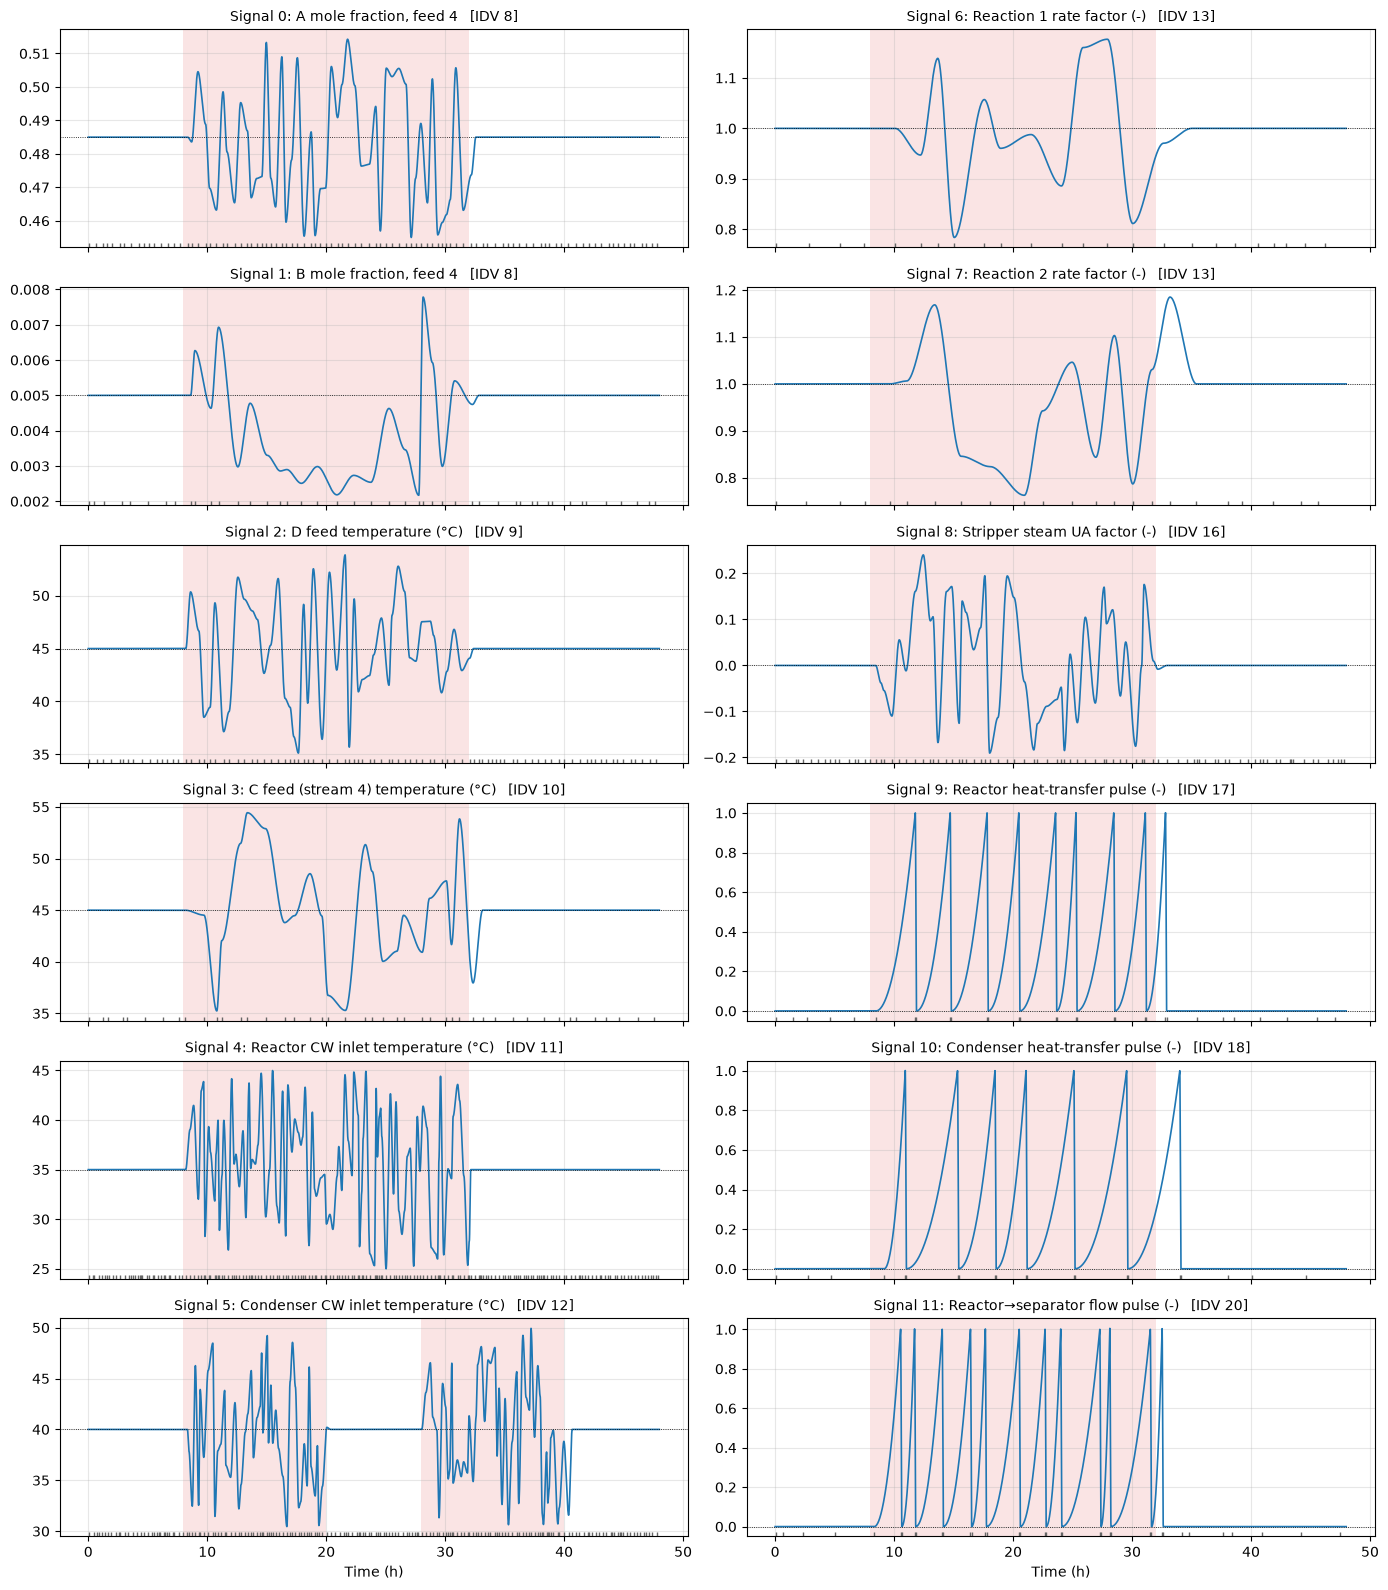

In [43]:
def shade(ax, on, color='tab:red', alpha=0.12):
    """Shade where boolean array `on` is True."""
    edges = np.flatnonzero(np.diff(np.r_[0, on.astype(int), 0]))
    for start, stop in zip(edges[::2], edges[1::2]):
        ax.axvspan(t[start], t[min(stop, len(t) - 1)], color=color, alpha=alpha, lw=0)

fig, axes = plt.subplots(6, 2, figsize=(14, 16), sharex=True)
for i, ax in enumerate(axes.T.ravel()):
    f = SIGNAL_IDV[i]
    shade(ax, idv_hist[:, f - 1] == 1)
    ax.plot(t, signals[:, i], lw=1.2)
    ax.axhline(SZERO[i], color='k', lw=0.6, ls=':')
    ax.plot(knots[i], np.full(len(knots[i]), 0), '|', color='0.4', ms=6,
            transform=ax.get_xaxis_transform())
    ax.set_title(f'Signal {i}: {SIGNAL_NAME[i]}   [IDV {f}]', fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel('Time (h)')
fig.tight_layout()
plt.show()

## Figure 2: resulting plant inputs (walks + step faults)

What `model()` actually uses, where step faults (IDV 1-7) add on top of the walk signals.
Shading colour shows which IDV is on: red = random-variation fault, blue = step fault.

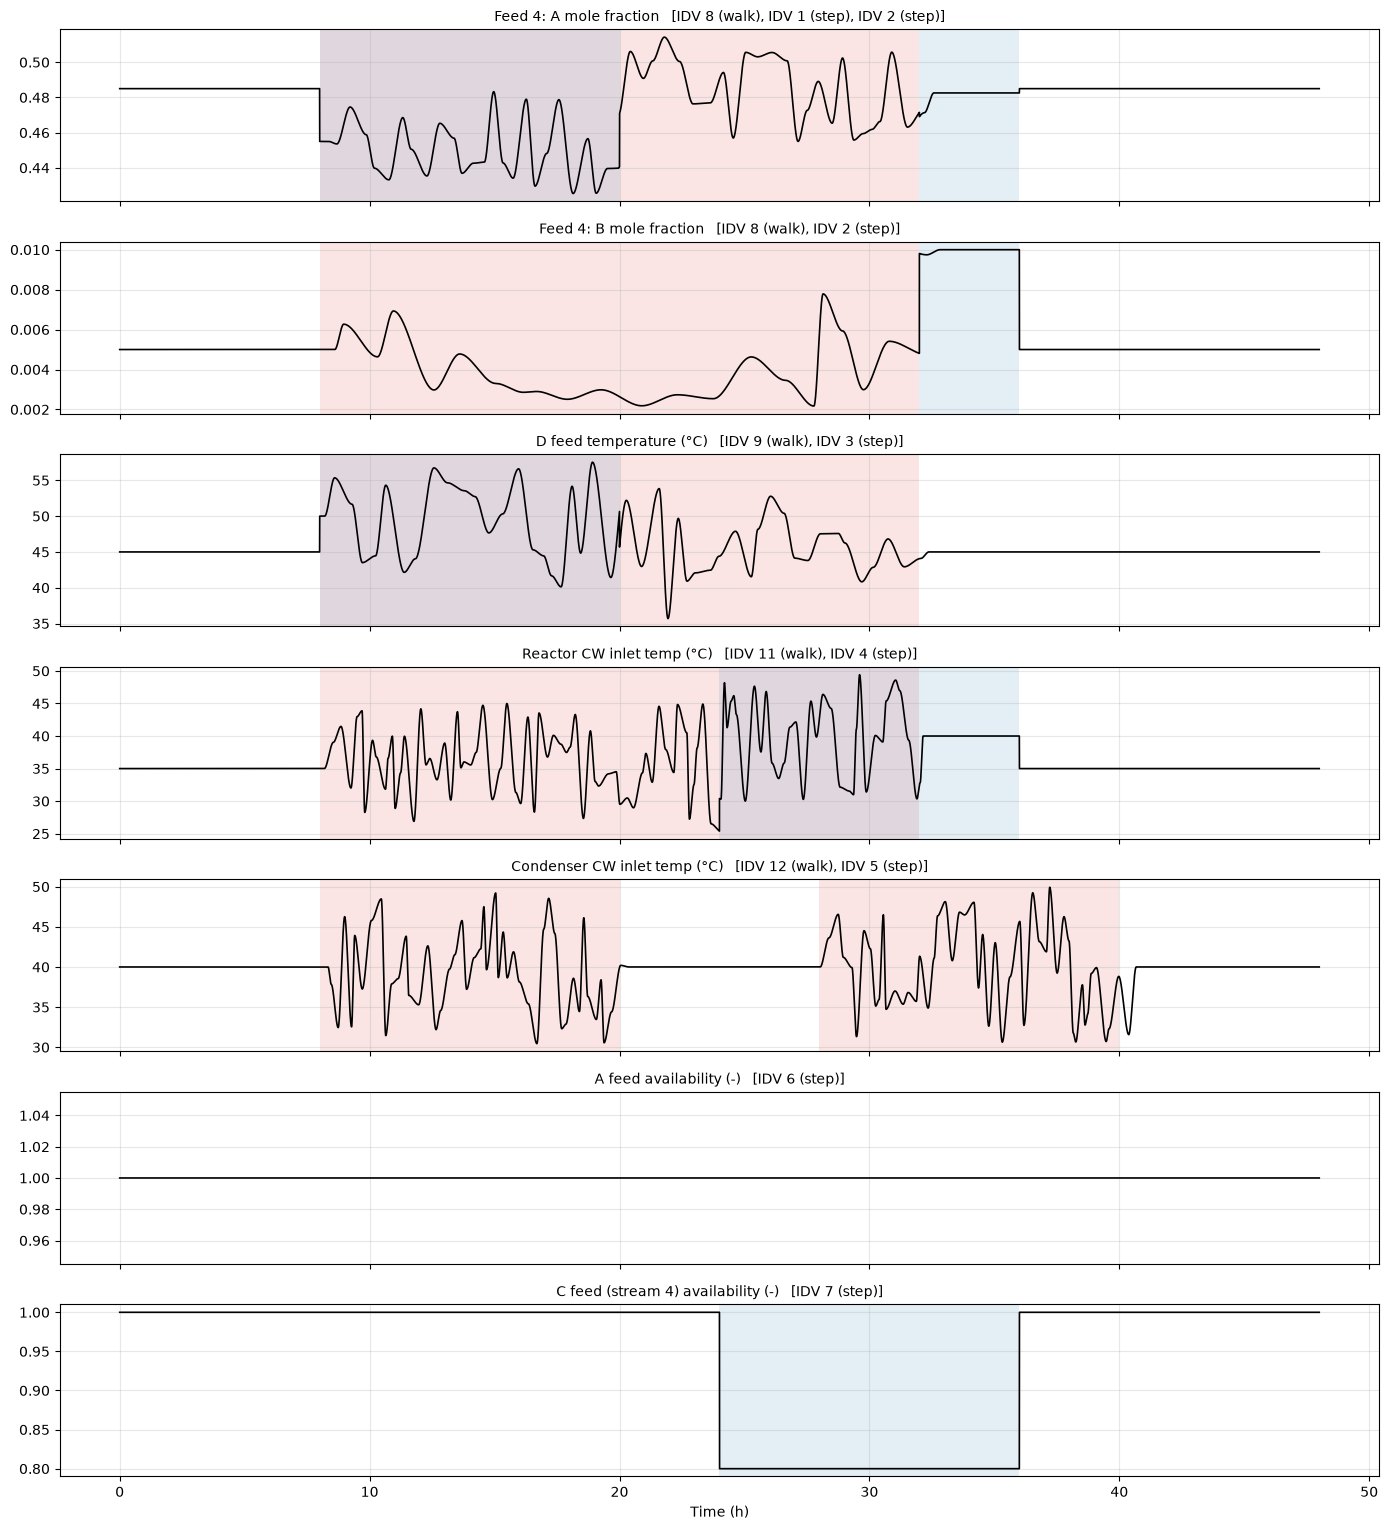

In [44]:
on = lambda f: idv_hist[:, f - 1]

inputs = {
    # name: (values, [walk IDVs], [step IDVs])
    'Feed 4: A mole fraction':        (signals[:, 0] - on(1) * 0.03 - on(2) * 2.43719e-3, [8], [1, 2]),
    'Feed 4: B mole fraction':        (signals[:, 1] + on(2) * 0.005,                     [8], [2]),
    'D feed temperature (°C)':        (signals[:, 2] + on(3) * 5.0,                       [9], [3]),
    'Reactor CW inlet temp (°C)':     (signals[:, 4] + on(4) * 5.0,                       [11], [4]),
    'Condenser CW inlet temp (°C)':   (signals[:, 5] + on(5) * 5.0,                       [12], [5]),
    'A feed availability (-)':        (1.0 - on(6),                                       [], [6]),
    'C feed (stream 4) availability (-)': (1.0 - 0.2 * on(7),                             [], [7]),
}

fig, axes = plt.subplots(len(inputs), 1, figsize=(14, 2.2 * len(inputs)), sharex=True)
for ax, (name, (vals, walk_f, step_f)) in zip(axes, inputs.items()):
    for f in walk_f:
        shade(ax, on(f) == 1, 'tab:red')
    for f in step_f:
        shade(ax, on(f) == 1, 'tab:blue')
    ax.plot(t, vals, lw=1.2, color='k')
    tags = ', '.join([f'IDV {f} (walk)' for f in walk_f] + [f'IDV {f} (step)' for f in step_f])
    ax.set_title(f'{name}   [{tags}]', fontsize=10)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Time (h)')
fig.tight_layout()
plt.show()

## Figure 3: fault schedule

Not shown above: stiction faults (IDV 14, 15, 19) act on valves, not on a signal, so they only appear here.

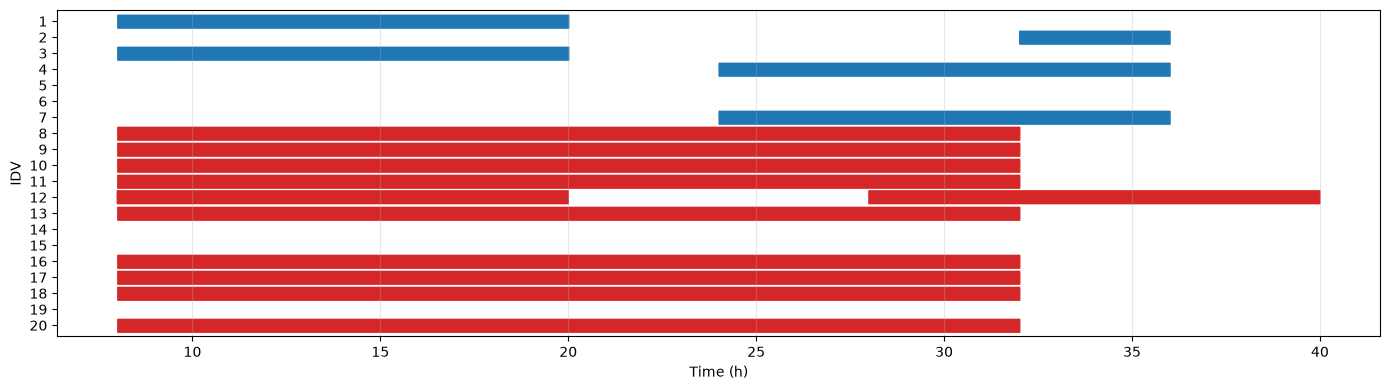

In [45]:
fig, ax = plt.subplots(figsize=(14, 4))
for f in range(1, 21):
    ax.fill_between(t, f - 0.4, f + 0.4, where=idv_hist[:, f - 1] == 1,
                    color='tab:blue' if f <= 7 else 'tab:red', step='post')
ax.set_yticks(range(1, 21))
ax.set_ylim(0.3, 20.7)
ax.invert_yaxis()
ax.set_ylabel('IDV')
ax.set_xlabel('Time (h)')
ax.grid(alpha=0.3, axis='x')
fig.tight_layout()
plt.show()